# EDA · ¿Cuán lejos está el aire porteño de las guías de la OMS?

**TP integrador de Análisis de Datos.** Rol: equipo de datos de una agencia de calidad ambiental que informa a
funcionarios, prensa y ciudadanía.

**Pregunta:** ¿cuán lejos está la calidad del aire de la Ciudad de Buenos Aires de las guías de la OMS (2021), y cómo
varía esa brecha entre estaciones, contaminantes, tipo de día y período?

| Subpregunta | Sección |
|---|---|
| 1. ¿Qué % de días se supera la guía diaria, por estación y contaminante? | 5 |
| 2. ¿Cuántas veces por encima de la guía anual están los promedios anuales? | 6 |
| 3. ¿Qué estación está peor y con qué contaminante? | 5, 6 |
| 4. ¿Cambia el cumplimiento entre hábiles, sábados, domingos y feriados? | 7, 8 |
| 5. ¿Hay estacionalidad? | 4, 7 |
| 6. ¿Cuánto condiciona la calidad de los datos a las conclusiones? | 2, 10 |

**Hipótesis:**
- **H1:** el NO₂ no alcanza la guía de la OMS, pero se mantiene dentro de sus **objetivos intermedios**: la mayoría
  de los días cumple el objetivo intermedio diario IT2 (50 µg/m³) y el promedio anual cumple al menos el IT1
  (40 µg/m³). El PM10 cumple la guía diaria casi todos los días.
- **H2:** La Boca es la estación más comprometida en NO₂.
- **H3:** los domingos y feriados la brecha se reduce de forma visible.

**Los escalones de la OMS.** La guía (AQG) es el nivel sin riesgo apreciable para la salud y es muy exigente. Por
eso la OMS define **objetivos intermedios** (IT1 el menos exigente … IT4 el más cercano a la guía) para medir el
avance. Para el NO₂: guía diaria 25 µg/m³, IT2 50, IT1 120; guía anual 10, IT3 20, IT2 30, IT1 40.

**De dónde salen los datos.** Este notebook lee las tablas finales de `data/final/` que genera el ETL
(`python -m src.etl`): el modelo estrella (dimensiones + `fact_medicion_diaria`) y los agregados de calidad e
indicadores. No recalcula reglas de negocio: las reglas viven en SQL (dbt) y acá se exploran y se grafican.
Todas las concentraciones se muestran en la unidad de la guía OMS (µg/m³; mg/m³ para el CO).

In [1]:
import logging
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)  # avisos de fuentes de Sweetviz

# Raíz del repo: funciona corriendo el notebook desde notebooks/ o desde la raíz
RAIZ = Path.cwd() if (Path.cwd() / "data" / "final").exists() else Path.cwd().parent
FINAL = RAIZ / "data" / "final"
FIGURAS = RAIZ / "reports" / "figures"
FIGURAS.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

# --- Estilo de los gráficos -----------------------------------------------------------------
# Superficie clara, tinta oscura, grilla tenue. Una estación = un color fijo en todo el TP
# (paleta validada para daltonismo). Los textos nunca van en el color de la serie.
SUPERFICIE, TINTA, TINTA_2, TENUE, GRILLA, EJE = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
COLOR_ESTACION = {"centenario": "#2a78d6", "cordoba": "#eb6834", "la_boca": "#1baf7a"}
# Niveles OMS: escala ordinal de un solo tono (más oscuro = más lejos de la guía) + gris para "cumple"
COLOR_NIVEL = {"AQG": "#c3c2b7", "IT4": "#86b6ef", "IT3": "#5598e7", "IT2": "#2a78d6", "IT1": "#1c5cab", "> IT1": "#0d366b"}

plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "axes.edgecolor": EJE, "axes.labelcolor": TINTA_2, "text.color": TINTA,
    "xtick.color": TENUE, "ytick.color": TENUE, "xtick.labelcolor": TINTA_2, "ytick.labelcolor": TINTA_2,
    "axes.grid": True, "grid.color": GRILLA, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": TINTA, "lines.linewidth": 2, "legend.frameon": False,
    "figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight",
})


def coma(x, dec=1):
    # Número con coma decimal (formato argentino) para etiquetas
    return f"{x:.{dec}f}".replace(".", ",")


def guardar(fig, nombre):
    fig.savefig(FIGURAS / f"{nombre}.png")
    print(f"Figura guardada: reports/figures/{nombre}.png")


def linea_guia(ax, valor, texto, estilo="--", color=TINTA_2, horizontal=True, lado="derecha", debajo=False):
    # Línea de referencia OMS con su etiqueta (siempre visible en los gráficos).
    # lado / debajo: dónde va la etiqueta, para que no tape los datos.
    if horizontal:
        ax.axhline(valor, color=color, linestyle=estilo, linewidth=1.2, zorder=3)
        x, ha, dx = (1, "right", -4) if lado == "derecha" else (0, "left", 4)
        ax.annotate(texto, xy=(x, valor), xycoords=("axes fraction", "data"), xytext=(dx, -4 if debajo else 4),
                    textcoords="offset points", ha=ha, va="top" if debajo else "bottom", fontsize=8.5, color=color,
                    bbox=dict(facecolor=SUPERFICIE, edgecolor="none", alpha=0.85, pad=1))
    else:
        ax.axvline(valor, color=color, linestyle=estilo, linewidth=1.2, zorder=3)
        ax.annotate(texto, xy=(valor, 1), xycoords=("data", "axes fraction"), xytext=(3, -2),
                    textcoords="offset points", ha="left", va="top", fontsize=8.5, color=color, rotation=90,
                    bbox=dict(facecolor=SUPERFICIE, edgecolor="none", alpha=0.85, pad=1))

In [2]:
# Tablas finales del ETL (Parquet: conserva los tipos, a diferencia del CSV)
leer = lambda nombre: pd.read_parquet(FINAL / f"{nombre}.parquet")

dim_estacion = leer("dim_estacion")
dim_contaminante = leer("dim_contaminante")
dim_calendario = leer("dim_calendario")
ref_oms = leer("ref_oms")
fact = leer("fact_medicion_diaria")
diario = leer("agg_cumplimiento_diario")
anual = leer("agg_anual")
rachas = leer("agg_rachas")
completitud_mensual = leer("agg_completitud_mensual")
calidad_resumen = leer("calidad_resumen")
violaciones = leer("calidad_violaciones")
outliers = leer("calidad_outliers")

NOMBRE = dim_estacion.set_index("id_estacion")["nombre"].to_dict()
ORDEN_ESTACIONES = dim_estacion.sort_values("orden")["id_estacion"].tolist()
GUIA = {(r.id_contaminante, r.promedio): r.guia_oms for r in ref_oms.itertuples()}
for nombre, df in [("fact_medicion_diaria", fact), ("agg_cumplimiento_diario", diario), ("agg_anual", anual)]:
    print(f"{nombre:25s} {df.shape[0]:>7,} filas × {df.shape[1]} columnas".replace(",", "."))

fact_medicion_diaria       30.120 filas × 17 columnas
agg_cumplimiento_diario     7.823 filas × 11 columnas
agg_anual                      36 filas × 29 columnas


## 1. Estructura y tipos

**Qué se busca:** entender la granularidad y los tipos antes de calcular nada.

El crudo (`data/raw/aire_publico.csv`) tiene **83.010 valores** de 279 PDF mensuales de la APrA: una fila por
estación × fecha × contaminante × estadístico, todo como texto. El ETL lo transforma en una **tabla de hechos en
formato largo**: una fila por fecha × estación × contaminante × ventana (`24h` = promedio diario, la que usa la
OMS; `8-16` = promedio de 8 a 16 h). La fact es una **grilla completa** (1.004 días × 3 estaciones ×
5 contaminantes × 2 ventanas = 30.120 filas): los días sin dato existen y llevan `tiene_dato = False` y el motivo.

In [3]:
print(fact.dtypes.to_string())
fact.head()

fecha               object
id_estacion            str
id_contaminante        str
ventana                str
valor_crudo            str
estado_valor           str
tiene_fila            bool
tiene_dato            bool
motivo_sin_dato        str
valor              float64
unidad                 str
valor_masa         float64
unidad_masa            str
es_imputado           bool
es_outlier            bool
umbral_outlier     float64
archivo_pdf            str


,fecha,id_estacion,id_contaminante,ventana,valor_crudo,estado_valor,tiene_fila,tiene_dato,motivo_sin_dato,valor,unidad,valor_masa,unidad_masa,es_imputado,es_outlier,umbral_outlier,archivo_pdf
0,2024-01-01,centenario,co,24h,"0,2",valido,True,True,NaN,0.2,ppm,0.229,mg/m³,False,False,1.10,co_centenario_enero_2024.pdf
1,2024-01-01,centenario,co,8-16,"0,2",valido,True,True,NaN,0.2,ppm,0.229,mg/m³,False,False,1.10,co_centenario_enero_2024.pdf
2,2024-01-01,centenario,no,24h,5,valido,True,True,NaN,5.0,ppb,6.136,µg/m³,False,False,75.00,nox_centenario_enero_2024.pdf
3,2024-01-01,centenario,no,8-16,4,valido,True,True,NaN,4.0,ppb,4.909,µg/m³,False,False,81.00,nox_centenario_enero_2024.pdf
4,2024-01-01,centenario,no2,24h,8,valido,True,True,NaN,8.0,ppb,15.053,µg/m³,False,False,37.25,nox_centenario_enero_2024.pdf


In [4]:
# Variables categóricas: cuántas filas hay de cada valor
for col in ["id_estacion", "id_contaminante", "ventana", "estado_valor", "motivo_sin_dato"]:
    print(fact[col].value_counts(dropna=False).rename_axis(col).to_frame("filas").T, "\n")

id_estacion  centenario  cordoba  la_boca
filas             10040    10040    10040 

id_contaminante    co    no   no2   nox  pm10
filas            6024  6024  6024  6024  6024 

ventana    24h   8-16
filas    15060  15060 

estado_valor  valido  sin_fila  sin_dato  bajo_limite_deteccion  invalido
filas          25751      2450      1914                      4         1 

motivo_sin_dato    NaN  sin_fila  sin_dato_fuente  nox_incoherente  promedio_incoherente  valor_trabado  mayor_que_nox  cero_sin_respaldo  fuera_de_max_min  \
filas            25449      2450             1914              202                    49             44              7                  3                 1   

motivo_sin_dato  texto_invalido  
filas                         1   



In [5]:
# Variables numéricas: valor en unidad original y en la unidad de la OMS, por contaminante (solo datos válidos)
(fact[fact.tiene_dato & (fact.ventana == "24h")]
    .groupby("id_contaminante")[["valor", "valor_masa"]]
    .describe(percentiles=[.25, .5, .75, .99]).round(2))

valor                                                     valor_masa                                                           
                  count   mean    std  min   25%   50%   75%     99%    max      count   mean    std    min    25%    50%     75%     99%     max
id_contaminante                                                                                                                                  
co               2694.0   0.47   0.23  0.1   0.3   0.4   0.6    1.20    1.7     2694.0   0.53   0.26   0.12   0.34   0.46    0.69    1.38    1.95
no               2462.0  25.21  22.04  1.0  10.0  19.0  34.0  100.39  276.0     2462.0  30.94  27.04   1.23  12.27  23.32   41.72  123.20  338.71
no2              2516.0  21.06   9.22  4.0  14.0  19.0  26.0   48.00   66.0     2516.0  39.63  17.36   7.53  26.34  35.75   48.92   90.32  124.19
nox              2457.0  46.17  27.93  6.0  28.0  39.0  58.0  142.44  333.0     2457.0  86.88  52.55  11.29  52.68  73.38  109.13  268.02  626.57
pm10             2613.0  23.40  10.41  4.0  17.0  21.0  28.0   57.00  134.0     2613.0  23.40  10.41   4.00  17.00  21.00   28.00   57.00  134.00

In [6]:
# Calendario: tipos de día del período (los feriados tienen prioridad sobre sábado/domingo)
dim_calendario.groupby(["tipo_dia_etiqueta"]).size().rename("días").to_frame().T

tipo_dia_etiqueta,Domingo,Feriado,Hábil,Sábado
días,138,53,674,139


### 1.1 Perfil automático con Sweetviz

**Sweetviz** genera un reporte HTML con el perfil de cada variable (tipo, nulos, distribución, valores frecuentes) y
las asociaciones entre variables. Es un primer barrido rápido; después el EDA guiado por las preguntas profundiza.

Se corre sobre una tabla **ancha**: una fila por estación y día, una columna por contaminante (promedio de 24 h, en
µg/m³; CO en mg/m³). Sobre la fact en formato largo no tendría sentido, porque mezclaría contaminantes en una
misma columna. Se generan dos reportes en `reports/`:
- `sweetviz_perfil.html`: perfil de todas las variables.
- `sweetviz_habil_vs_no_habil.html`: compara días hábiles contra sábados, domingos y feriados, con el NO₂ como
  variable objetivo (insumo para H3). Sweetviz no acepta nulos en la variable objetivo: solo entran días con NO₂.

In [7]:
import sweetviz as sv

ancho_sv = (fact[fact.ventana == "24h"]
            .pivot_table(index=["id_estacion", "fecha"], columns="id_contaminante", values="valor_masa")
            .reset_index()
            .merge(dim_calendario[["fecha", "tipo_dia", "estacion_del_anio", "mes"]], on="fecha"))
ancho_sv["estacion"] = ancho_sv["id_estacion"].map(NOMBRE)
ancho_sv = ancho_sv[["estacion", "tipo_dia", "estacion_del_anio", "mes", "no2", "pm10", "co", "no", "nox"]]

# rc_context: Sweetviz cambia la configuración de matplotlib (fuentes); así se restaura al terminar
with plt.rc_context():
    perfil = sv.analyze(ancho_sv)
    perfil.show_html(str(RAIZ / "reports" / "sweetviz_perfil.html"), open_browser=False, layout="vertical")

    con_no2 = ancho_sv.dropna(subset=["no2"])
    comparacion = sv.compare_intra(con_no2, con_no2["tipo_dia"] == "habil", ["Hábil", "Sábado, domingo o feriado"],
                                   target_feat="no2")
    comparacion.show_html(str(RAIZ / "reports" / "sweetviz_habil_vs_no_habil.html"), open_browser=False,
                          layout="vertical")

/home/user/nox-ciudad/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


                                             |          | [  0%]   00:00 -> (? left)

[Summarizing dataframe]                      |          | [  0%]   00:00 -> (? left)

Feature: estacion                            |█         | [ 10%]   00:00 -> (00:00 left)

Feature: estacion                            |██        | [ 20%]   00:00 -> (00:00 left)

Feature: tipo_dia                            |██        | [ 20%]   00:00 -> (00:00 left)

... (47 outputs left out)

Done! Use 'show' commands to display/save.   |          | [  0%]   00:01 -> (? left)

Done! Use 'show' commands to display/save.   |██████████| [100%]   00:01 -> (00:00 left)

Done! Use 'show' commands to display/save.   |██████████| [100%]   00:01 -> (00:00 left)

Report /home/user/nox-ciudad/reports/sweetviz_habil_vs_no_habil.html was generated.


**Qué muestra Sweetviz y qué no:** confirma los tipos, la proporción de nulos por contaminante (sección 2), las
distribuciones asimétricas (sección 3) y la asociación fuerte entre NO, NOx y NO₂ (sección 9). En la comparación,
los días no hábiles tienen menos NO₂. Lo que **no** sabe es el dominio: no conoce la guía de la OMS, la regla del
75% ni los huecos de la fuente. Por eso el resto del EDA se hace a mano, guiado por las subpreguntas.

**Qué se concluye:**
- Las fechas ya son `date` y los valores, `float`: la conversión de texto (coma decimal, `s/d`, `<4`) se hizo en
  el staging SQL. Los identificadores quedaron en snake_case y sin tildes (`la_boca`, `no2`).
- Hay **variables categóricas** (estación, contaminante, ventana, tipo de día, estación del año) y **numéricas**
  (concentraciones), además de una **serie temporal diaria**.
- Las columnas `nombre_feriado` y `evento` del calendario están vacías la mayor parte del tiempo: son **nulos
  estructurales** ("no aplica"), no datos faltantes.

## 2. Calidad de los datos

**Qué se busca:** saber cuánto dato hay, qué se descartó y por qué, antes de sacar conclusiones (subpregunta 6).

### 2.1 Qué pasó con cada celda de los PDF

In [8]:
tabla = (calidad_resumen.pivot_table(index="categoria", columns="id_contaminante", values="n_valores",
                                     aggfunc="sum", fill_value=0)
         [["no2", "pm10", "co", "no", "nox"]])
tabla["total"] = tabla.sum(axis=1)
tabla.sort_values("total", ascending=False)

id_contaminante,no2,pm10,co,no,nox,total
categoria,,,,,,
valido,15256,15827,16249,14892,15032,77256
sin_dato_fuente,776,1440,996,776,775,4763
valido_imputado,8,256,83,101,0,448
nox_incoherente,0,0,0,107,180,287
valor_trabado,0,0,0,132,0,132
promedio_incoherente,0,8,0,32,57,97
mayor_que_nox,10,0,0,6,0,16
cero_sin_respaldo,0,0,0,4,3,7
fuera_de_max_min,0,0,0,0,3,3


- **93% de los valores son válidos tal cual**; 5,7% son `s/d` en la planilla; 0,5% son "bajo el límite de
  detección" (`<4`), que se imputan como **límite / 2** (descartarlos sesgaría los promedios hacia arriba).
- Las reglas de validación física descartan **menos del 1%**, casi todo en NO y NOx.

### 2.2 Completitud por estación × contaminante × mes

Es el gráfico central de calidad: muestra qué meses no tienen datos y, por la **regla del 75%**, qué indicadores
anuales no se pueden calcular.

Figura guardada: reports/figures/01_completitud_heatmap.png


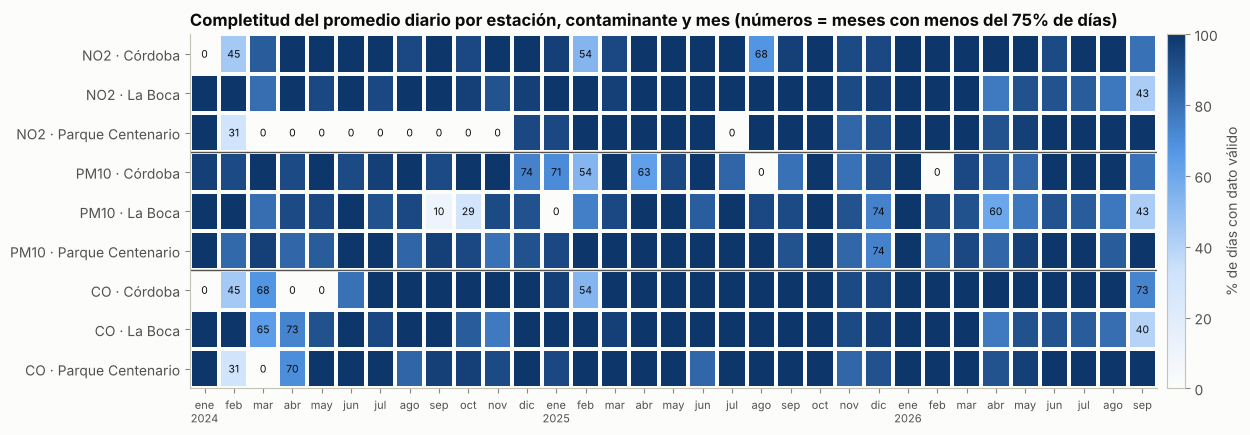

In [9]:
cm = completitud_mensual[completitud_mensual.id_contaminante.isin(["no2", "pm10", "co"])].copy()
cm["fila"] = cm.id_contaminante.str.upper() + " · " + cm.id_estacion.map(NOMBRE)
orden_filas = [f"{c} · {NOMBRE[e]}" for c in ["NO2", "PM10", "CO"] for e in ORDEN_ESTACIONES]
matriz = cm.pivot(index="fila", columns="anio_mes", values="completitud").loc[orden_filas]

fig, ax = plt.subplots(figsize=(13, 4.6))
cmap = LinearSegmentedColormap.from_list("completitud", ["#fcfcfb", "#cde2fb", "#5598e7", "#0d366b"])
malla = ax.pcolormesh(matriz.values * 100, cmap=cmap, vmin=0, vmax=100, edgecolors=SUPERFICIE, linewidth=1.5)
ax.set_yticks(np.arange(len(matriz)) + 0.5, matriz.index)
ax.invert_yaxis()
meses = pd.to_datetime(matriz.columns)
MES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
ax.set_xticks(np.arange(len(meses)) + 0.5,
              [f"{MES[m.month - 1]}\n{m.year}" if m.month == 1 else MES[m.month - 1] for m in meses], fontsize=8)
ax.grid(False)
for i in range(matriz.shape[0]):
    for j in range(matriz.shape[1]):
        v = matriz.values[i, j]
        if v < 0.75:  # solo se rotulan los meses que no cumplen el 75%
            ax.text(j + 0.5, i + 0.5, f"{v*100:.0f}", ha="center", va="center", fontsize=7.5, color=TINTA)
for k in (3, 6):
    ax.axhline(k, color=TINTA_2, linewidth=1)
barra = fig.colorbar(malla, ax=ax, pad=0.01, fraction=0.03)
barra.set_label("% de días con dato válido")
ax.set_title("Completitud del promedio diario por estación, contaminante y mes "
             "(números = meses con menos del 75% de días)")
guardar(fig, "01_completitud_heatmap")
plt.show()

In [10]:
# Qué indicadores anuales deja afuera la regla del 75%
anual.loc[~anual.es_valido, ["id_estacion", "id_contaminante", "periodo", "n_dias_con_dato", "completitud"]]

,id_estacion,id_contaminante,periodo,n_dias_con_dato,completitud
4,centenario,no2,2024,69,0.1885
12,cordoba,co,2024,242,0.6612


**Lo que queda afuera y por qué:**
- **NO₂ de Parque Centenario en 2024** (19% de días): la APrA no publicó los informes de óxidos de nitrógeno de
  marzo a noviembre de 2024 (y tampoco julio de 2025). No hay promedio anual válido de Centenario para 2024.
- **CO de Córdoba en 2024** (66%): faltan enero, abril y mayo.
- Otros huecos que no alcanzan para invalidar el año: PM10 de Córdoba (agosto de 2025 y febrero de 2026), PM10 de
  La Boca (septiembre y octubre de 2024 casi vacíos, enero de 2025 vacío) y septiembre de 2026 en La Boca (~40%).
- **No faltan días completos:** las tres estaciones tienen al menos un contaminante publicado los 1.004 días. Los
  huecos son por contaminante (un PDF mensual que no se publicó).

### 2.3 Reglas de validación física y el "día 8"

In [11]:
# SQL directo sobre los Parquet con DuckDB: violaciones por regla y por día del mes
violaciones_pq = (FINAL / "calidad_violaciones.parquet").as_posix()
print(duckdb.sql(f'''
    select regla, count(*) as violaciones, count(*) filter (where se_descarta) as descartadas
    from '{violaciones_pq}' group by regla order by violaciones desc
''').df().to_string(index=False))
print()
print(duckdb.sql(f'''
    select day(fecha) as dia_del_mes,
           count(*) filter (where regla = 'nox_incoherente') as incoherencias_nox,
           count(*) filter (where regla = 'valor_trabado')   as valores_trabados
    from '{violaciones_pq}' group by 1 order by 2 desc limit 4
''').df().to_string(index=False))

               regla  violaciones  descartadas
     nox_incoherente          588          402
       valor_trabado          132          132
promedio_incoherente          100          100
   no2_mayor_que_nox           10           10
    no_mayor_que_nox           10           10
   cero_sin_respaldo            7            7
    fuera_de_max_min            3            3
      texto_invalido            1            1

 dia_del_mes  incoherencias_nox  valores_trabados
           8                255               132
           9                 54                 0
          11                 21                 0
          23                 18                 0


- Las incoherencias **NOx ≠ NO + NO₂** se concentran en el **día 8 de cada mes** (255 de 588). En 22 de esos días
  el NO tiene **el mismo valor en los 6 estadísticos** (máximo horario = mínimo = promedios): un analizador "trabado"
  o un error de carga en la planilla, imposible en una ciudad.
- Decisión: la incoherencia de la suma invalida **NO y NOx**, no el NO₂, porque el NO₂ pasa sus propios controles
  (su promedio de 24 h coincide con el de los tres bloques de 8 h y está dentro del rango horario). Así no se pierden
  días del contaminante principal. Si el NO₂ supera al NOx (10 casos), sí se descarta.

### 2.4 Valores atípicos (outliers)

Criterio: valor > Q3 + 3·IQR de su estación × contaminante × ventana. **Se marcan, no se borran.**

In [12]:
print(outliers.groupby(["id_contaminante", "ventana"]).size().rename("outliers").to_frame().T.to_string())
# ¿El mismo día es atípico en varias estaciones? Entonces es un episodio atmosférico, no un error de un equipo.
(outliers[outliers.ventana == "24h"]
    .groupby(["fecha", "id_contaminante"])
    .agg(estaciones=("id_estacion", "nunique"), max_veces_mediana=("veces_mediana", "max"))
    .query("estaciones >= 2").sort_values(["estaciones", "max_veces_mediana"], ascending=False).head(8))

id_contaminante  co       no      no2      nox      pm10     
ventana         24h 8-16 24h 8-16 24h 8-16 24h 8-16  24h 8-16
outliers         10   11  41   30   4    3  24   19   14   29


,,estaciones,max_veces_mediana
fecha,id_contaminante,,
2025-06-19,no,3,14.2
2025-06-18,no,3,7.7
2025-06-19,nox,3,6.7
2025-11-18,pm10,3,5.8
2024-07-12,pm10,3,4.3
2025-11-19,pm10,3,4.3
2025-06-18,nox,3,4.1
2025-06-06,no,2,8.5


In [13]:
# Los casos más extremos, para revisar a mano
outliers.sort_values("veces_mediana", ascending=False).head(6)[
    ["fecha", "id_estacion", "id_contaminante", "ventana", "valor", "unidad", "mediana", "veces_mediana", "nombre_dia"]]

,fecha,id_estacion,id_contaminante,ventana,valor,unidad,mediana,veces_mediana,nombre_dia
150,2026-05-23,cordoba,no,8-16,424.0,ppb,29.0,14.6,sábado
93,2025-06-19,la_boca,no,24h,242.0,ppb,17.0,14.2,jueves
84,2025-06-19,centenario,no,24h,149.0,ppb,12.0,12.4,jueves
149,2026-05-23,cordoba,no,24h,276.0,ppb,26.0,10.6,sábado
154,2026-05-23,cordoba,nox,8-16,492.0,ppb,49.0,10.0,sábado
106,2025-07-02,la_boca,no,24h,168.0,ppb,17.0,9.9,miércoles


**Decisión sobre los outliers:**
- Los días más extremos aparecen **a la vez en las tres estaciones** (18 y 19 de junio de 2025 en NO/NOx; 12 de
  julio de 2024 y 18-19 de noviembre de 2025 en PM10): son episodios reales (por ejemplo, inversiones térmicas o
  humo/polvo regional), no fallas de un equipo. Borrarlos subestimaría justo lo que la guía de 24 h quiere detectar.
- El caso aislado más llamativo es **Córdoba, sábado 23/05/2026**: NO de 424 ppb en el bloque de 8 a 16 h (14 veces
  la mediana), sin correlato en las otras estaciones. Pasa las reglas físicas (el NOx acompaña), así que se conserva
  marcado; afecta al NO y al NOx, que no se comparan con la OMS.
- Del NO₂ hay solo 4 outliers diarios en Córdoba: no cambian ningún indicador.

## 3. Distribuciones por contaminante y estación

**Qué se busca:** cómo se reparten los valores diarios y dónde cae la guía de 24 h dentro de esa distribución.

In [14]:
# Estadísticas descriptivas del promedio diario (unidad OMS), por contaminante y estación
desc = (diario.groupby(["id_contaminante", "id_estacion"])["valor"]
        .describe(percentiles=[.5, .9, .99]).round(1))
desc["asimetria"] = diario.groupby(["id_contaminante", "id_estacion"])["valor"].skew().round(2)
desc

count  mean   std   min   50%   90%   99%    max  asimetria
id_contaminante id_estacion                                                             
co              centenario   916.0   0.5   0.2   0.1   0.5   0.8   1.3    1.6       1.50
                cordoba      854.0   0.7   0.3   0.1   0.7   1.0   1.5    1.9       0.72
                la_boca      924.0   0.4   0.2   0.1   0.3   0.7   1.0    1.8       1.89
no2             centenario   662.0  26.4   9.0   7.5  26.3  39.5  50.8   58.3       0.49
                cordoba      910.0  36.9  12.1  11.3  35.8  52.7  69.4  109.1       1.05
                la_boca      944.0  51.5  18.3  13.2  50.8  77.1  95.2  124.2       0.47
pm10            centenario   937.0  21.4   9.7   4.0  19.0  34.0  52.0  104.0       2.06
                cordoba      855.0  25.0  10.0   7.0  23.0  37.0  57.0  134.0       2.93
                la_boca      821.0  23.9  11.2   4.0  22.0  38.0  60.6  122.0       2.01

Figura guardada: reports/figures/02_distribuciones_boxplot.png


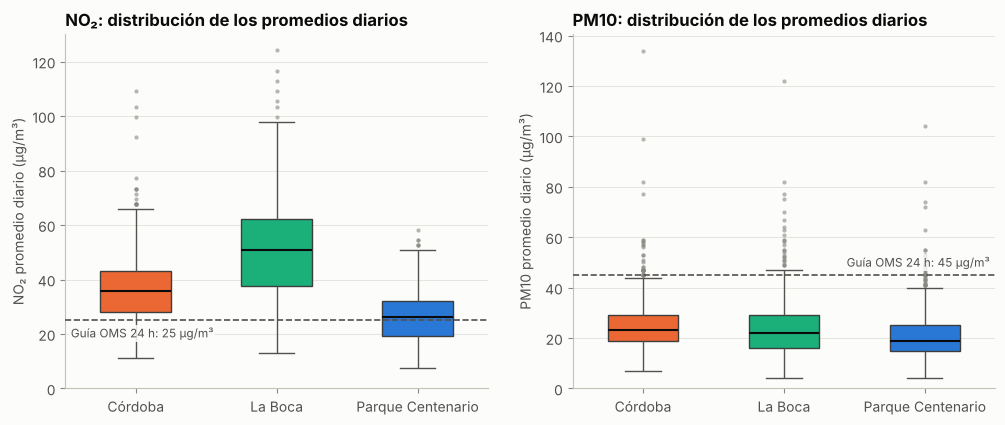

In [15]:
# seaborn trabaja directo sobre el DataFrame: x = categoría, y = valor, hue = color por categoría
diario["estacion"] = diario["id_estacion"].map(NOMBRE)
ORDEN_NOMBRES = [NOMBRE[e] for e in ORDEN_ESTACIONES]
PALETA = {NOMBRE[e]: COLOR_ESTACION[e] for e in ORDEN_ESTACIONES}

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, cont, titulo in [(ejes[0], "no2", "NO₂"), (ejes[1], "pm10", "PM10")]:
    sns.boxplot(data=diario[diario.id_contaminante == cont], x="estacion", y="valor", hue="estacion",
                order=ORDEN_NOMBRES, palette=PALETA, width=0.5, saturation=1, ax=ax,
                medianprops=dict(color=TINTA, linewidth=1.5), whiskerprops=dict(color=TINTA_2),
                capprops=dict(color=TINTA_2),
                flierprops=dict(marker="o", markersize=3, markerfacecolor=TENUE, markeredgecolor="none", alpha=0.6))
    ax.set_xlabel("")
    linea_guia(ax, GUIA[(cont, "24h")], f"Guía OMS 24 h: {GUIA[(cont, '24h')]:.0f} µg/m³",
               lado="izquierda" if cont == "no2" else "derecha", debajo=cont == "no2")
    ax.set_ylabel(f"{titulo} promedio diario (µg/m³)")
    ax.set_title(f"{titulo}: distribución de los promedios diarios")
    ax.set_ylim(bottom=0)
guardar(fig, "02_distribuciones_boxplot")
plt.show()

Figura guardada: reports/figures/03_histograma_no2.png


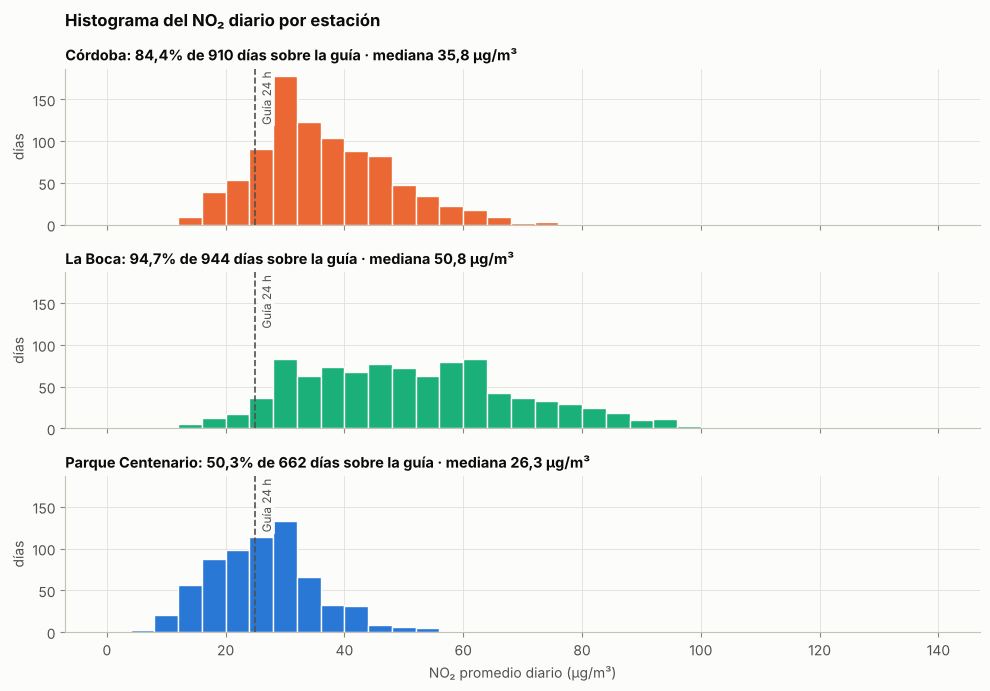

In [16]:
no2 = diario[diario.id_contaminante == "no2"]
fig, ejes = plt.subplots(3, 1, figsize=(10, 7), sharex=True, sharey=True)
bordes = np.arange(0, 141, 4)
for ax, e in zip(ejes, ORDEN_ESTACIONES):
    v = no2[no2.id_estacion == e]["valor"]
    sns.histplot(x=v, bins=bordes, color=COLOR_ESTACION[e], edgecolor=SUPERFICIE, linewidth=1, alpha=1, ax=ax)
    linea_guia(ax, 25, "Guía 24 h", horizontal=False)
    ax.set_title(f"{NOMBRE[e]}: {coma(100 * (v > 25).mean())}% de {len(v)} días sobre la guía · mediana {coma(v.median())} µg/m³",
                 fontsize=10.5)
    ax.set_ylabel("días")
ejes[-1].set_xlabel("NO₂ promedio diario (µg/m³)")
fig.suptitle("Histograma del NO₂ diario por estación", x=0.07, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
guardar(fig, "03_histograma_no2")
plt.show()

**Qué se concluye:**
- El **NO₂** está casi entero por encima de la guía de 24 h en La Boca y Córdoba, pero casi siempre por debajo del
  objetivo intermedio IT2 (50 µg/m³) en Córdoba y Centenario. En La Boca **la mediana (51 µg/m³) está justo en el
  IT2**: la mitad de los días lo supera. Centenario está repartido a ambos lados de la guía.
- El **PM10** está casi siempre por debajo de 45 µg/m³ (las cajas quedan abajo de la guía); lo que la supera son
  colas de pocos días.
- Las distribuciones son **asimétricas a la derecha** (más días bajos y algunos picos): conviene reportar mediana y
  percentiles, no solo promedios. Los puntos sueltos son los días atípicos de la sección 2.4.

## 4. Serie temporal diaria con la guía OMS

**Qué se busca:** ver la evolución, los huecos y la estacionalidad en el tiempo. Puntos = días; línea = media móvil
de 30 días (se corta donde no hay datos, en lugar de inventar una continuidad).

Figura guardada: reports/figures/04_serie_no2.png


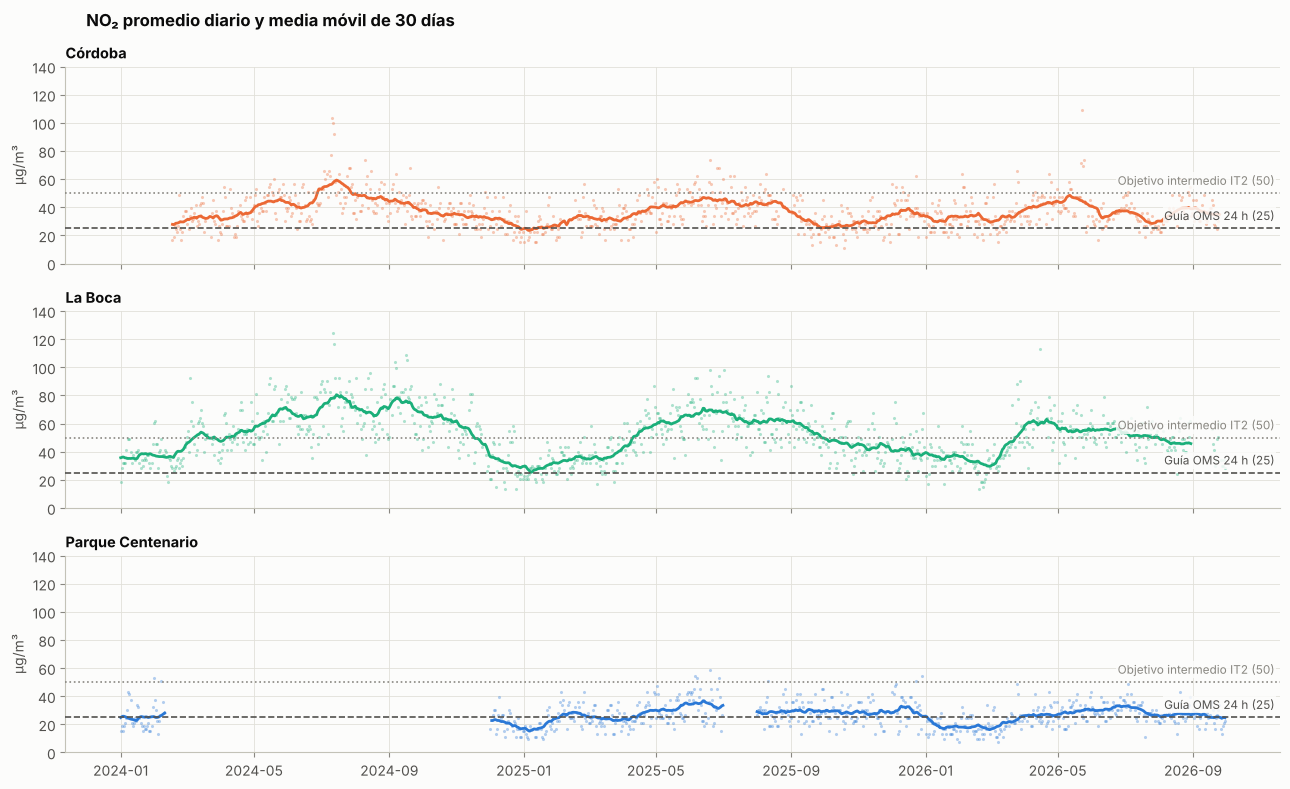

In [17]:
def serie(cont, titulo, guia, extra=None, nombre_fig=None, ymax=None):
    fechas = pd.date_range(dim_calendario.fecha.min(), dim_calendario.fecha.max(), freq="D")
    fig, ejes = plt.subplots(3, 1, figsize=(13, 8), sharex=True, sharey=True)
    for ax, e in zip(ejes, ORDEN_ESTACIONES):
        s = (diario[(diario.id_contaminante == cont) & (diario.id_estacion == e)]
             .set_index(pd.to_datetime(diario.loc[(diario.id_contaminante == cont) & (diario.id_estacion == e), "fecha"]))["valor"]
             .reindex(fechas))
        media = s.rolling(30, min_periods=15, center=True).mean()
        ax.scatter(s.index, s, s=5, color=COLOR_ESTACION[e], alpha=0.35, linewidths=0)
        ax.plot(media.index, media, color=COLOR_ESTACION[e], linewidth=2)
        linea_guia(ax, guia, f"Guía OMS 24 h ({guia:.0f})")
        if extra:
            linea_guia(ax, extra[0], extra[1], estilo=":", color=TENUE)
        ax.set_title(NOMBRE[e], fontsize=10.5)
        ax.set_ylabel("µg/m³")
        if ymax:
            ax.set_ylim(0, ymax)
    fig.suptitle(titulo, x=0.07, ha="left", fontweight="bold", fontsize=12)
    fig.tight_layout()
    guardar(fig, nombre_fig)
    plt.show()

serie("no2", "NO₂ promedio diario y media móvil de 30 días", 25, extra=(50, "Objetivo intermedio IT2 (50)"),
      nombre_fig="04_serie_no2", ymax=140)

Figura guardada: reports/figures/05_serie_pm10.png


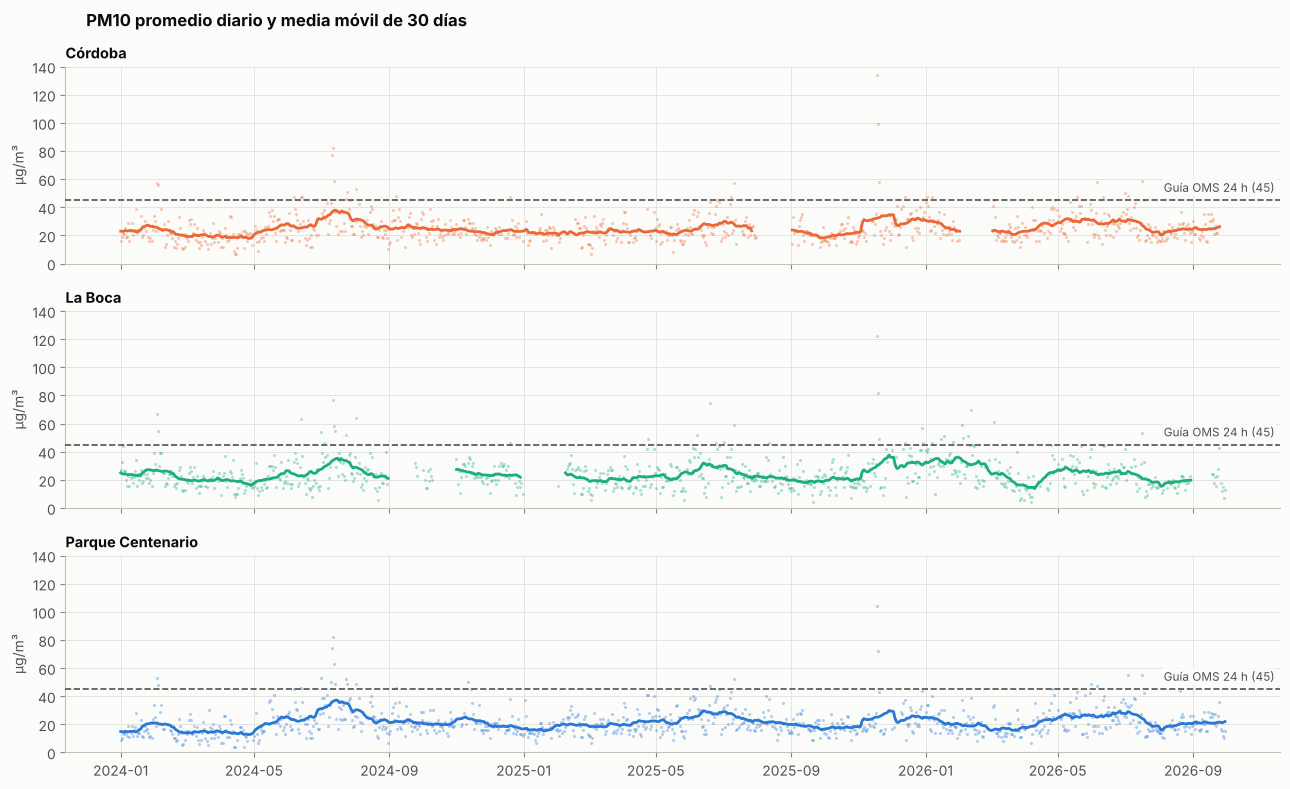

In [18]:
serie("pm10", "PM10 promedio diario y media móvil de 30 días", 45, nombre_fig="05_serie_pm10", ymax=140)

**Qué se concluye:**
- La media móvil de 30 días del NO₂ de **La Boca nunca baja de la guía de 25 µg/m³** en todo el período (su mínimo,
  en enero de 2025, es 25,4) y la de **Córdoba solo baja 13 días**, a comienzos de enero de 2025. La de La Boca pasa
  los meses fríos por encima del objetivo intermedio IT2 (50 µg/m³).
- Hay una **estacionalidad clara**: el NO₂ sube en otoño-invierno y baja en verano, en las tres estaciones.
- El hueco de Centenario (marzo a noviembre de 2024 y julio de 2025) se ve como un corte en la serie.
- El PM10 vive debajo de la guía y la cruza en picos cortos, varios compartidos por las tres estaciones
  (episodios regionales).

## 5. ¿En qué escalón de la OMS está cada día? (subpreguntas 1 y 3, H1)

Cada día con dato se ubica en el escalón más exigente que cumple: **guía** (AQG), o el objetivo intermedio que
corresponda, o "> IT1" si no cumple ni el menos exigente. Denominador: **días con dato válido** (un día sin dato no
cuenta como día "limpio").

In [19]:
ORDEN_NIVEL = ["AQG", "IT4", "IT3", "IT2", "IT1", "> IT1"]
niveles_dia = (diario[diario.id_contaminante.isin(["no2", "pm10"])]
               .groupby(["id_contaminante", "id_estacion"])["nivel_oms"]
               .value_counts(normalize=True).mul(100).unstack(fill_value=0)
               .reindex(columns=ORDEN_NIVEL, fill_value=0).round(1))
niveles_dia

nivel_oms                     AQG  IT4  IT3   IT2   IT1  > IT1
id_contaminante id_estacion                                   
no2             centenario   49.7  0.0  0.0  48.9   1.4    0.0
                cordoba      15.6  0.0  0.0  72.1  12.3    0.0
                la_boca       5.3  0.0  0.0  44.4  50.2    0.1
pm10            centenario   97.7  1.2  1.0   0.1   0.1    0.0
                cordoba      96.7  1.6  1.2   0.4   0.1    0.0
                la_boca      95.9  1.6  2.2   0.2   0.1    0.0

Figura guardada: reports/figures/06_niveles_oms_diarios.png


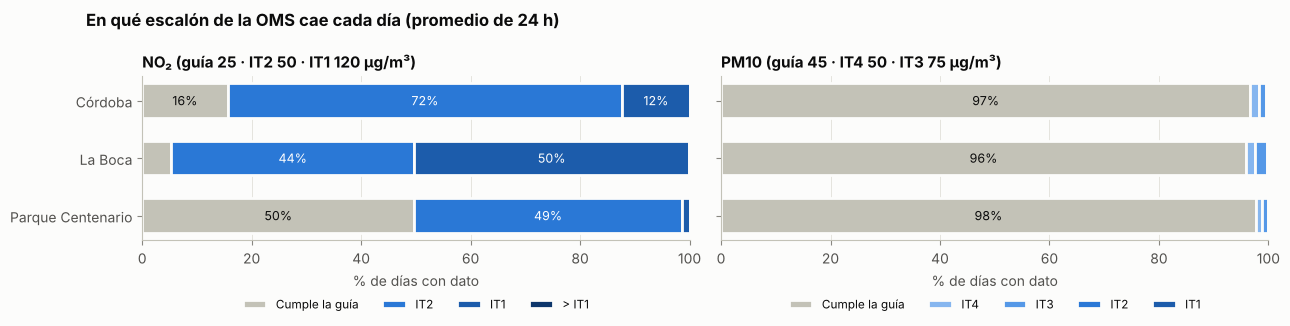

In [20]:
# Barras 100% apiladas: qué parte de los días cae en cada escalón (más oscuro = más lejos de la guía)
fig, ejes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
etiquetas_nivel = {"AQG": "Cumple la guía", "IT4": "IT4", "IT3": "IT3", "IT2": "IT2", "IT1": "IT1", "> IT1": "> IT1"}
for ax, cont, titulo in [(ejes[0], "no2", "NO₂ (guía 25 · IT2 50 · IT1 120 µg/m³)"),
                         (ejes[1], "pm10", "PM10 (guía 45 · IT4 50 · IT3 75 µg/m³)")]:
    izquierda = np.zeros(3)
    for nivel in ORDEN_NIVEL:
        valores = np.array([niveles_dia.loc[(cont, e), nivel] for e in ORDEN_ESTACIONES])
        if valores.sum() == 0:
            continue
        ax.barh(ORDEN_NOMBRES, valores, left=izquierda, height=0.6, color=COLOR_NIVEL[nivel],
                edgecolor=SUPERFICIE, linewidth=2, label=etiquetas_nivel[nivel])
        for y, (v, x0) in enumerate(zip(valores, izquierda)):
            if v >= 6:
                ax.text(x0 + v / 2, y, f"{coma(v, 0)}%", ha="center", va="center", fontsize=9,
                        color=TINTA if nivel == "AQG" else "#ffffff")
        izquierda += valores
    ax.set_xlim(0, 100)
    ax.set_xlabel("% de días con dato")
    ax.set_title(titulo, fontsize=11)
    ax.grid(axis="y", visible=False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=5, fontsize=8.5)
ejes[0].invert_yaxis()
fig.suptitle("En qué escalón de la OMS cae cada día (promedio de 24 h)", x=0.07, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
guardar(fig, "06_niveles_oms_diarios")
plt.show()

**Qué se concluye:**
- **NO₂:** ninguna estación cumple la guía diaria la mayoría de los días, pero el **objetivo intermedio IT2
  (50 µg/m³) se cumple el 98,6% de los días en Parque Centenario y el 87,7% en Córdoba**. En **La Boca, solo el
  49,7%**: la mitad de los días supera incluso el IT2. El IT1 (120 µg/m³) se cumple prácticamente siempre (un solo
  día lo supera en La Boca, con 124 µg/m³).
- **PM10:** cumple la guía diaria entre el 95,9% y el 97,7% de los días.

### 5.1 Matriz de escalones por estación y año

Lo mismo, año por año y **acumulado**: qué % de días cumple la guía y cada objetivo intermedio (un día que cumple la
guía cumple también todos los IT). Sale de `indicadores.agg_cumplimiento_niveles`. Los períodos con menos de 75% de
días con dato quedan vacíos ("—"). 2026 es parcial (enero a septiembre).

Figura guardada: reports/figures/06b_matriz_niveles_no2.png


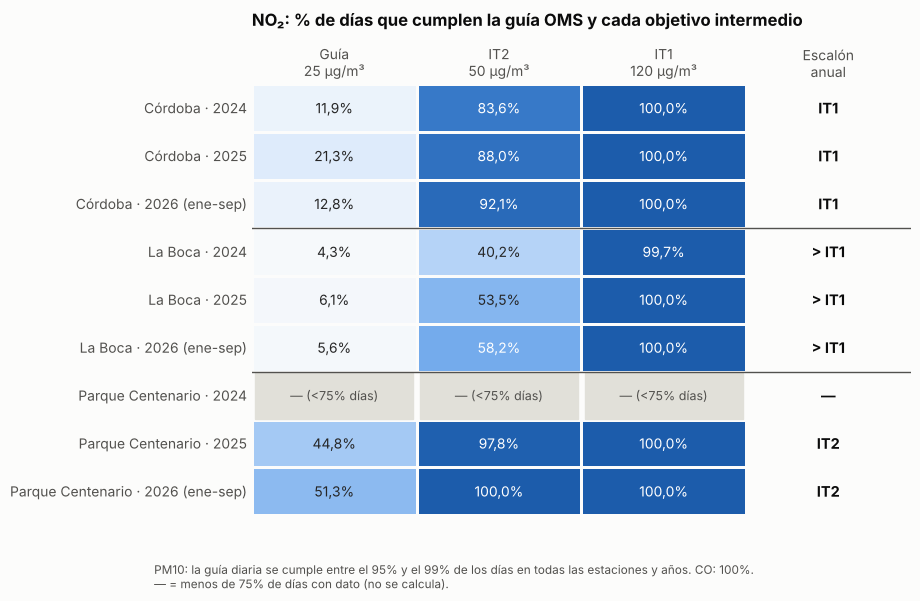

In [21]:
matriz_niveles = leer("agg_cumplimiento_niveles")
anual_niv = anual.set_index(["id_estacion", "id_contaminante", "id_periodo"])["nivel_oms"]
periodos_m = [("2024", "2024"), ("2025", "2025"), ("2026", "2026 (ene-sep)")]
niveles_no2 = [("AQG", "Guía\n25 µg/m³"), ("IT2", "IT2\n50 µg/m³"), ("IT1", "IT1\n120 µg/m³")]

filas, etiquetas_filas, escalon = [], [], []
for e in ORDEN_ESTACIONES:
    for id_p, txt in periodos_m:
        sub = matriz_niveles[(matriz_niveles.id_contaminante == "no2") & (matriz_niveles.id_estacion == e)
                             & (matriz_niveles.id_periodo == id_p)].set_index("nivel")
        filas.append([100 * sub.loc[n, "pct_dias_cumple"] if pd.notna(sub.loc[n, "pct_dias_cumple"]) else np.nan
                      for n, _ in niveles_no2])
        etiquetas_filas.append(f"{NOMBRE[e]} · {txt}")
        escalon.append(anual_niv.get((e, "no2", id_p)) if pd.notna(anual_niv.get((e, "no2", id_p))) else "—")
tabla_m = pd.DataFrame(filas, index=etiquetas_filas, columns=[t for _, t in niveles_no2])

fig, ax = plt.subplots(figsize=(8.5, 5.6))
textos = tabla_m.map(lambda v: "—" if pd.isna(v) else f"{coma(v)}%")
cmap_m = LinearSegmentedColormap.from_list("cumple", ["#fcfcfb", "#cde2fb", "#5598e7", "#1c5cab"])
sns.heatmap(tabla_m, annot=textos, fmt="", cmap=cmap_m, vmin=0, vmax=100, linewidths=2, linecolor=SUPERFICIE,
            cbar=False, annot_kws={"fontsize": 10}, ax=ax)  # sin barra de color: los % van escritos
ax.grid(False)
for i, fila in enumerate(tabla_m.values):  # períodos sin datos suficientes: gris con texto
    for j, v in enumerate(fila):
        if np.isnan(v):
            ax.add_patch(plt.Rectangle((j + 0.02, i + 0.02), 0.96, 0.96, color=GRILLA, zorder=2))
            ax.text(j + 0.5, i + 0.5, "— (<75% días)", ha="center", va="center", fontsize=9, color=TINTA_2, zorder=3)
for i, txt in enumerate(escalon):  # columna de texto: escalón del promedio anual
    ax.text(3.5, i + 0.5, txt, ha="center", va="center", fontsize=10.5, color=TINTA, fontweight="bold")
ax.text(3.5, -0.08, "Escalón\nanual", ha="center", va="bottom", fontsize=10, color=TINTA_2)
ax.set_xlim(0, 4)
for k in (3, 6):
    ax.axhline(k, color=TINTA_2, linewidth=1)
ax.set_xlabel("")
ax.set_ylabel("")
ax.xaxis.tick_top()
ax.tick_params(axis="both", length=0)
ax.set_title("NO₂: % de días que cumplen la guía OMS y cada objetivo intermedio", pad=42)
fig.text(0.01, -0.02, "PM10: la guía diaria se cumple entre el 95% y el 99% de los días en todas las estaciones y años. "
         "CO: 100%.\n— = menos de 75% de días con dato (no se calcula).", fontsize=8.5, color=TINTA_2)
guardar(fig, "06b_matriz_niveles_no2")
plt.show()

In [22]:
# PM10 y CO: la misma matriz en tabla (casi todo cerca de 100%, por eso no va al gráfico)
(matriz_niveles[matriz_niveles.id_contaminante.isin(["pm10", "co"]) & (matriz_niveles.id_periodo != "movil_12m")]
 .assign(pct=lambda x: (100 * x.pct_dias_cumple).round(1))
 .pivot_table(index=["id_contaminante", "id_estacion", "id_periodo"], columns=["orden_exigencia", "nivel"], values="pct")
 .droplevel(0, axis=1))

nivel                                     AQG   IT4    IT3    IT2    IT1
id_contaminante id_estacion id_periodo                                  
co              centenario  2024        100.0   NaN    NaN    NaN  100.0
                            2025        100.0   NaN    NaN    NaN  100.0
                            2026        100.0   NaN    NaN    NaN  100.0
                cordoba     2025        100.0   NaN    NaN    NaN  100.0
                            2026        100.0   NaN    NaN    NaN  100.0
                la_boca     2024        100.0   NaN    NaN    NaN  100.0
                            2025        100.0   NaN    NaN    NaN  100.0
                            2026        100.0   NaN    NaN    NaN  100.0
pm10            centenario  2024         95.8  98.2   99.7  100.0  100.0
                            2025         98.9  99.1   99.7   99.7  100.0
                            2026         98.4  99.2  100.0  100.0  100.0
                cordoba     2024         96.3  98.0   99.4  100.0  100.0
                            2025         97.9  98.6   99.3   99.6  100.0
                            2026         96.0  98.7  100.0  100.0  100.0
                la_boca     2024         96.3  97.0   99.7  100.0  100.0
                            2025         95.8  98.0   99.4   99.7  100.0
                            2026         95.4  97.2  100.0  100.0  100.0

**Qué se concluye:**
- **Centenario y Córdoba cumplen el IT2 diario casi todos los días en todos los años** (84% a 100%) y el IT1 siempre;
  su promedio anual se mantiene en el mismo escalón los tres años (IT2 y IT1).
- **La Boca mejora año a año en el IT2 diario: 40% → 54% → 58% de los días** (2024 → 2025 → 2026 parcial), aunque su
  promedio anual sigue por encima del IT1. Sin datos meteorológicos no se puede atribuir a una mejora real de las
  emisiones (un año más ventoso o lluvioso también baja el NO₂), y a septiembre de 2026 le falta más de la mitad de
  los días.
- La guía diaria se cumple poco: entre 4% y 51% de los días según estación y año.

### 5.2 % de días por encima de la guía diaria

El mismo dato, resumido en "días que superan la guía": es la forma más directa de comunicarlo, pero conviene leerlo
junto con los escalones.

In [23]:
pct = (diario.groupby(["id_contaminante", "id_estacion"])
       .agg(dias_con_dato=("valor", "size"), dias_sobre_guia=("supera_guia", "sum"), pct=("supera_guia", "mean")))
pct["pct"] = (100 * pct["pct"]).round(1)
pct

dias_con_dato  dias_sobre_guia   pct
id_contaminante id_estacion                                      
co              centenario             916                0   0.0
                cordoba                854                0   0.0
                la_boca                924                0   0.0
no2             centenario             662              333  50.3
                cordoba                910              768  84.4
                la_boca                944              894  94.7
pm10            centenario             937               22   2.3
                cordoba                855               28   3.3
                la_boca                821               34   4.1

Figura guardada: reports/figures/07_pct_dias_sobre_guia.png


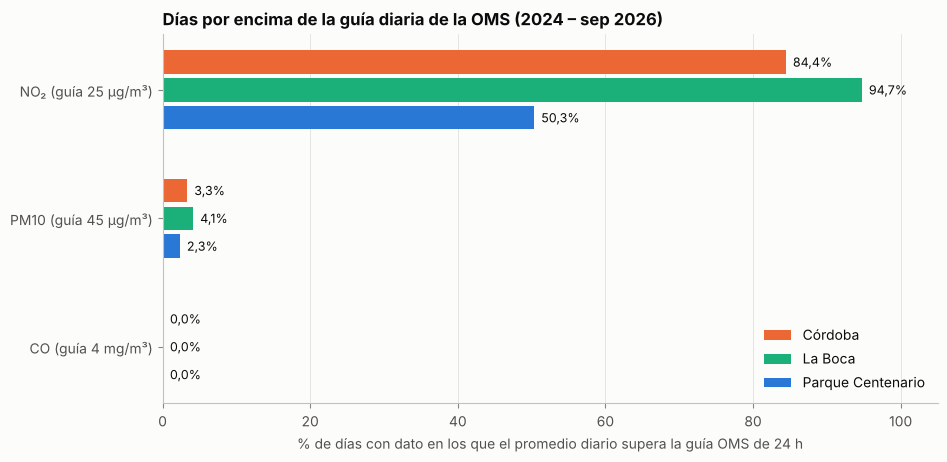

In [24]:
fig, ax = plt.subplots(figsize=(10, 4.8))
contaminantes = [("no2", "NO₂ (guía 25 µg/m³)"), ("pm10", "PM10 (guía 45 µg/m³)"), ("co", "CO (guía 4 mg/m³)")]
alto, sep = 0.26, 1.2
for i, (cont, etiqueta) in enumerate(contaminantes):
    for j, e in enumerate(ORDEN_ESTACIONES):
        y = i * sep + (j - 1) * alto
        v = pct.loc[(cont, e), "pct"]
        ax.barh(y, v, height=alto - 0.04, color=COLOR_ESTACION[e], label=NOMBRE[e] if i == 0 else None)
        ax.text(v + 1, y, f"{coma(v)}%", va="center", fontsize=9, color=TINTA)
ax.set_yticks([i * sep for i in range(3)], [c[1] for c in contaminantes])
ax.invert_yaxis()
ax.set_xlim(0, 105)
ax.set_xlabel("% de días con dato en los que el promedio diario supera la guía OMS de 24 h")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
ax.set_title("Días por encima de la guía diaria de la OMS (2024 – sep 2026)")
guardar(fig, "07_pct_dias_sobre_guia")
plt.show()

In [25]:
# La definición formal de la OMS: el percentil 99 anual de los valores diarios contra la guía de 24 h
p99 = anual[anual.tipo_periodo != "movil_12m"].pivot_table(
    index=["id_contaminante", "id_estacion"], columns="id_periodo", values="p99_veces_guia_24h")
print("Percentil 99 anual / guía de 24 h (más de 1 = no se cumple la guía en sentido formal):")
p99.loc[["no2", "pm10", "co"]]

Percentil 99 anual / guía de 24 h (más de 1 = no se cumple la guía en sentido formal):


id_periodo                   2024  2025  2026
id_contaminante id_estacion                  
no2             centenario    NaN  2.11  1.73
                cordoba      3.07  2.53  2.81
                la_boca      4.18  3.72  3.42
pm10            centenario   1.18  1.02  1.06
                cordoba      1.26  1.27  1.16
                la_boca      1.40  1.31  1.29
co              centenario   0.26  0.32  0.26
                cordoba       NaN  0.37  0.37
                la_boca      0.33  0.17  0.24

**Qué se concluye (subpreguntas 1 y 3):**
- **NO₂:** La Boca supera la guía diaria el **94,7%** de los días, Córdoba el **84,4%** y Parque Centenario el
  **50,3%** (pero, como se vio arriba, Centenario y Córdoba casi siempre cumplen el IT2). Con el criterio formal
  (P99 anual), el NO₂ de La Boca está entre **3,4 y 4,2 veces** la guía.
- **PM10:** entre 2,3% y 4,1% de los días. **Pero el P99 anual supera los 45 µg/m³ en todas las estaciones y años**
  (1,02 a 1,40 veces): con la definición formal, tampoco se cumple la guía de 24 h del PM10.
- **CO:** nunca se acerca a la guía (el P99 es menos de 0,4 veces los 4 mg/m³). No es un problema en la Ciudad.
- Nota: los porcentajes preliminares del enunciado (~91 / 75 / 33%) dividían por todas las filas, incluidos los
  días sin dato. Con el denominador correcto son más altos, sobre todo en Centenario (50% y no 33%).

In [26]:
# Rachas: días seguidos por encima de la guía (técnica gaps and islands, en indicadores.agg_rachas)
rachas[rachas.es_racha_maxima].sort_values(["id_contaminante", "dias"], ascending=[True, False])

,id_estacion,id_contaminante,fecha_inicio,fecha_fin,dias,es_racha_maxima
250,la_boca,no2,2025-03-25,2025-10-26,216,True
155,cordoba,no2,2025-05-02,2025-08-20,111,True
85,centenario,no2,2026-06-19,2026-07-10,22,True
104,centenario,pm10,2024-07-10,2024-07-14,5,True
207,cordoba,pm10,2024-07-11,2024-07-13,3,True
214,cordoba,pm10,2025-11-18,2025-11-20,3,True
273,la_boca,pm10,2024-07-12,2024-07-14,3,True
284,la_boca,pm10,2025-11-18,2025-11-20,3,True


La racha más larga de NO₂: **La Boca, 216 días seguidos** sobre la guía (25/03/2025 a 26/10/2025); Córdoba 111 días
y Centenario 22. Una racha se corta con un día bajo la guía **o sin dato** (criterio conservador).

## 6. Promedio anual contra la guía anual y los objetivos intermedios (subpregunta 2)

Solo períodos con al menos 75% de días con dato. **2026 es parcial** (enero a septiembre, sin primavera ni verano):
para compararlo con un año completo se usan los **últimos 12 meses** (octubre 2025 a septiembre 2026).

In [27]:
cols = ["id_estacion", "periodo", "completitud", "promedio_anual", "guia_anual", "veces_guia_anual",
        "nivel_oms", "proximo_nivel", "ug_para_proximo_nivel"]
anual[anual.id_contaminante == "no2"][cols].sort_values(["id_estacion", "periodo"])

,id_estacion,periodo,completitud,promedio_anual,guia_anual,veces_guia_anual,nivel_oms,proximo_nivel,ug_para_proximo_nivel
4,centenario,2024,0.1885,NaN,10.0,NaN,NaN,NaN,NaN
5,centenario,2025,0.8877,28.13,10.0,2.81,IT2,IT3,8.13
6,centenario,2026 (parcial: 01/01 a 30/09),0.9853,25.16,10.0,2.52,IT2,IT3,5.16
7,centenario,Últimos 12 meses (10/2025 a 09/2026),0.9671,26.17,10.0,2.62,IT2,IT3,6.17
16,cordoba,2024,0.8497,39.24,10.0,3.92,IT1,IT2,9.24
17,cordoba,2025,0.9151,35.24,10.0,3.52,IT1,IT2,5.24
18,cordoba,2026 (parcial: 01/01 a 30/09),0.9707,36.18,10.0,3.62,IT1,IT2,6.18
19,cordoba,Últimos 12 meses (10/2025 a 09/2026),0.9671,34.98,10.0,3.50,IT1,IT2,4.98
28,la_boca,2024,0.9590,56.45,10.0,5.65,> IT1,IT1,16.45
29,la_boca,2025,0.9890,49.87,10.0,4.99,> IT1,IT1,9.87


In [28]:
anual[anual.id_contaminante == "pm10"][cols].sort_values(["id_estacion", "periodo"])

,id_estacion,periodo,completitud,promedio_anual,guia_anual,veces_guia_anual,nivel_oms,proximo_nivel,ug_para_proximo_nivel
8,centenario,2024,0.9126,20.99,15.0,1.40,IT3,IT4,0.99
9,centenario,2025,0.9507,21.47,15.0,1.43,IT3,IT4,1.47
10,centenario,2026 (parcial: 01/01 a 30/09),0.9377,21.89,15.0,1.46,IT3,IT4,1.89
11,centenario,Últimos 12 meses (10/2025 a 09/2026),0.9178,21.87,15.0,1.46,IT3,IT4,1.87
20,cordoba,2024,0.9508,24.61,15.0,1.64,IT3,IT4,4.61
21,cordoba,2025,0.7644,24.42,15.0,1.63,IT3,IT4,4.42
22,cordoba,2026 (parcial: 01/01 a 30/09),0.8352,26.50,15.0,1.77,IT3,IT4,6.50
23,cordoba,Últimos 12 meses (10/2025 a 09/2026),0.8521,26.57,15.0,1.77,IT3,IT4,6.57
32,la_boca,2024,0.8115,23.76,15.0,1.58,IT3,IT4,3.76
33,la_boca,2025,0.8384,23.60,15.0,1.57,IT3,IT4,3.60


Figura guardada: reports/figures/08_promedio_anual_vs_oms.png


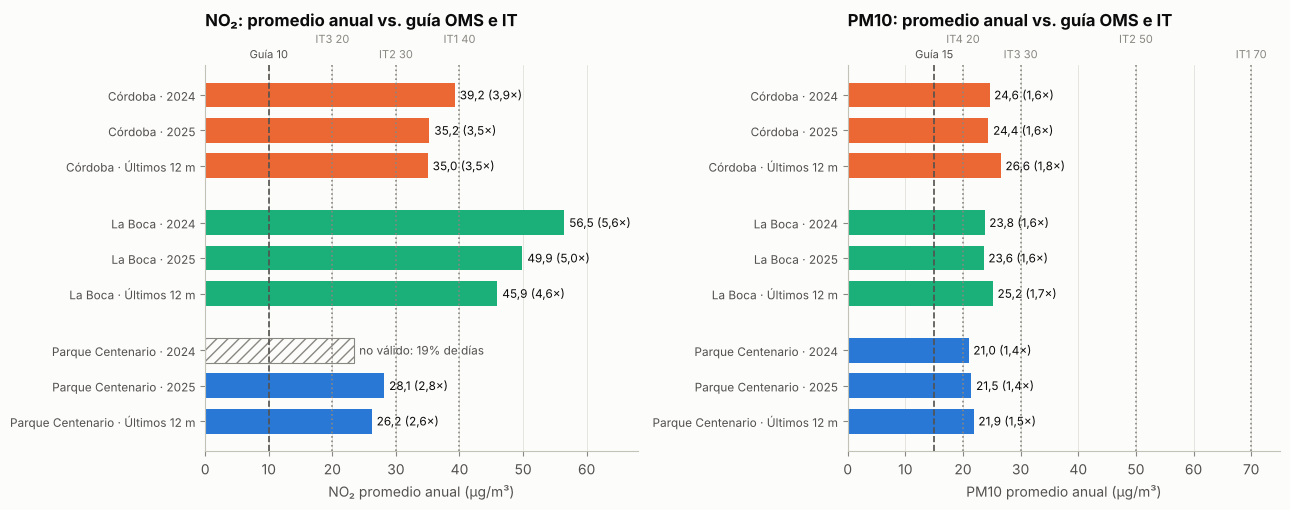

In [29]:
niveles = leer("ref_oms_niveles")
periodos = [("2024", "2024"), ("2025", "2025"), ("movil_12m", "Últimos 12 m")]
fig, ejes = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, cont, titulo in [(ejes[0], "no2", "NO₂"), (ejes[1], "pm10", "PM10")]:
    etiquetas, y = [], 0
    for e in ORDEN_ESTACIONES:
        for id_p, txt in periodos:
            fila = anual[(anual.id_contaminante == cont) & (anual.id_estacion == e) & (anual.id_periodo == id_p)].iloc[0]
            if fila.es_valido:
                ax.barh(y, fila.promedio_anual, height=0.7, color=COLOR_ESTACION[e])
                ax.text(fila.promedio_anual + 0.8, y, f"{coma(fila.promedio_anual)} ({coma(fila.promedio_anual / fila.guia_anual)}×)",
                        va="center", fontsize=8.5, color=TINTA)
            else:
                ax.barh(y, fila.promedio_referencial, height=0.7, color="none", edgecolor=TENUE, hatch="///", linewidth=0.8)
                ax.text(fila.promedio_referencial + 0.8, y, f"no válido: {coma(100 * fila.completitud, 0)}% de días",
                        va="center", fontsize=8.5, color=TINTA_2)
            etiquetas.append((y, f"{NOMBRE[e]} · {txt}"))
            y += 1
        y += 0.6
    ax.set_yticks([p for p, _ in etiquetas], [t for _, t in etiquetas], fontsize=8.5)
    ax.invert_yaxis()
    for k, r in enumerate(niveles[(niveles.id_contaminante == cont) & (niveles.promedio == "anual")]
                          .sort_values("umbral").itertuples()):
        estilo = "--" if r.nivel == "AQG" else ":"
        color = TINTA_2 if r.nivel == "AQG" else TENUE
        ax.axvline(r.umbral, color=color, linestyle=estilo, linewidth=1.2, zorder=3)
        ax.annotate(f"{'Guía' if r.nivel == 'AQG' else r.nivel} {r.umbral:.0f}", xy=(r.umbral, 1.0),
                    xycoords=("data", "axes fraction"), xytext=(0, 3 + 11 * (k % 2)), textcoords="offset points",
                    ha="center", va="bottom", fontsize=8, color=color)
    ax.set_xlabel(f"{titulo} promedio anual (µg/m³)")
    ax.set_title(f"{titulo}: promedio anual vs. guía OMS e IT", pad=28)
    ax.grid(axis="y", visible=False)
ejes[0].set_xlim(0, 68)
ejes[1].set_xlim(0, 75)
fig.tight_layout()
guardar(fig, "08_promedio_anual_vs_oms")
plt.show()

**Qué se concluye (subpregunta 2):**
- **NO₂, últimos 12 meses:** ninguna estación cumple la guía anual de 10 µg/m³, pero dos están en escalones
  intermedios: **Parque Centenario cumple el IT2** (26,2 µg/m³, 2,6 veces la guía; le faltan ~6 µg/m³ para el IT3) y
  **Córdoba cumple el IT1** (35,0 µg/m³, 3,5 veces; le faltan ~5 µg/m³ para el IT2). **La Boca no cumple ni el IT1**
  (45,9 µg/m³, 4,6 veces la guía): le faltan ~6 µg/m³ para llegar al primer escalón.
- En 2024, La Boca llegó a **56,5 µg/m³ (5,6 veces)**.
- **PM10:** entre 21,9 y 26,6 µg/m³ en los últimos 12 meses, **1,5 a 1,8 veces** la guía anual de 15 µg/m³: las
  tres estaciones están en el **IT3**. El PM10 casi no supera la guía diaria, pero tampoco cumple la anual.

## 7. Cumplimiento por tipo de día y por estación del año (subpreguntas 4 y 5)

**Qué se busca:** si la brecha depende de la actividad urbana (H3) y de la época del año.

In [30]:
d = diario.merge(dim_calendario[["fecha", "tipo_dia_etiqueta", "orden_tipo_dia", "estacion_del_anio",
                                 "orden_estacion_del_anio", "nombre_dia", "dia_semana", "mes"]], on="fecha")
no2d = d[d.id_contaminante == "no2"]
tipo = (no2d.groupby(["id_estacion", "orden_tipo_dia", "tipo_dia_etiqueta"])
        .agg(dias=("valor", "size"), no2_promedio=("valor", "mean"), pct_sobre_guia=("supera_guia", "mean"))
        .reset_index())
tipo["variacion_vs_habil_pct"] = 100 * (tipo.no2_promedio / tipo.groupby("id_estacion").no2_promedio.transform("first") - 1)
tipo["pct_sobre_guia"] *= 100
tipo.round(1)

,id_estacion,orden_tipo_dia,tipo_dia_etiqueta,dias,no2_promedio,pct_sobre_guia,variacion_vs_habil_pct
0,centenario,1,Hábil,442,28.3,59.3,0.0
1,centenario,2,Sábado,93,24.4,39.8,-13.7
2,centenario,3,Domingo,91,20.8,26.4,-26.7
3,centenario,4,Feriado,36,22.6,27.8,-20.1
4,cordoba,1,Hábil,607,38.8,90.4,0.0
5,cordoba,2,Sábado,127,36.1,78.0,-7.0
6,cordoba,3,Domingo,126,30.6,68.3,-21.3
7,cordoba,4,Feriado,50,31.5,68.0,-18.7
8,la_boca,1,Hábil,632,53.8,96.8,0.0
9,la_boca,2,Sábado,130,49.9,93.8,-7.1


Figura guardada: reports/figures/09_tipo_dia.png


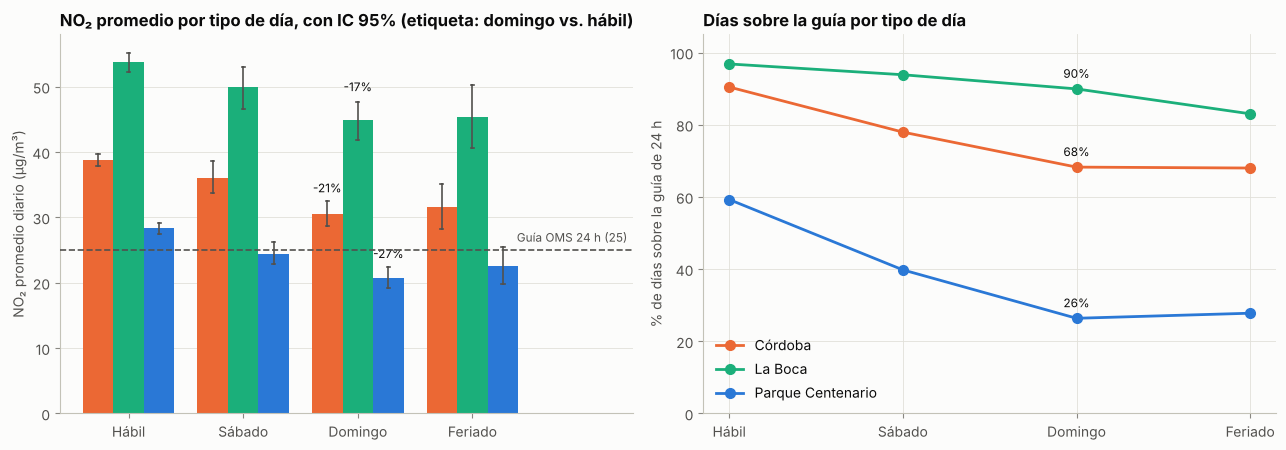

In [31]:
tipos = ["Hábil", "Sábado", "Domingo", "Feriado"]
no2d = no2d.assign(estacion=no2d.id_estacion.map(NOMBRE))
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.6))
# seaborn calcula el promedio de cada grupo y su intervalo de confianza del 95% (las rayitas)
sns.barplot(data=no2d, x="tipo_dia_etiqueta", y="valor", hue="estacion", order=tipos, hue_order=ORDEN_NOMBRES,
            palette=PALETA, saturation=1, errorbar=("ci", 95), seed=0, err_kws={"color": TINTA_2, "linewidth": 1.2},
            capsize=0.08, ax=ejes[0], legend=False)
ancho = 0.8 / 3
for j, e in enumerate(ORDEN_ESTACIONES):
    t = tipo[tipo.id_estacion == e].set_index("tipo_dia_etiqueta").loc[tipos]
    domingo = no2d[(no2d.id_estacion == e) & (no2d.tipo_dia_etiqueta == "Domingo")]["valor"]
    techo_ic = domingo.mean() + 1.96 * domingo.std() / np.sqrt(len(domingo))  # aprox. del IC para ubicar la etiqueta
    ejes[0].text(2 + (j - 1) * ancho, techo_ic + 1, f"{coma(t.variacion_vs_habil_pct.iloc[2], 0)}%",
                 ha="center", va="bottom", fontsize=8.5, color=TINTA)
    ejes[1].plot(range(4), t.pct_sobre_guia, marker="o", markersize=7, color=COLOR_ESTACION[e], label=NOMBRE[e])
    ejes[1].annotate(f"{coma(t.pct_sobre_guia.iloc[2], 0)}%", (2, t.pct_sobre_guia.iloc[2]), xytext=(0, 8),
                     textcoords="offset points", ha="center", fontsize=8.5, color=TINTA)
linea_guia(ejes[0], 25, "Guía OMS 24 h (25)")
ejes[0].set_xlim(-0.6, 4.4)  # espacio a la derecha para la etiqueta de la guía
ejes[0].set_xlabel("")
ejes[0].set_ylabel("NO₂ promedio diario (µg/m³)")
ejes[0].set_title("NO₂ promedio por tipo de día, con IC 95% (etiqueta: domingo vs. hábil)")
ejes[1].legend(loc="lower left")
ejes[0].grid(axis="x", visible=False)
ejes[1].set_xticks(range(4), tipos)
ejes[1].set_ylim(0, 105)
ejes[1].set_ylabel("% de días sobre la guía de 24 h")
ejes[1].set_title("Días sobre la guía por tipo de día")
fig.tight_layout()
guardar(fig, "09_tipo_dia")
plt.show()

**Qué se concluye (subpregunta 4, H3):**
- Con menos actividad el NO₂ baja: el **domingo** está **27% (Centenario), 21% (Córdoba) y 17% (La Boca)** por
  debajo del día hábil; los feriados se parecen a los domingos y los sábados quedan en el medio. Los intervalos de
  confianza del día hábil y del domingo no se superponen: la diferencia no es ruido. Es consistente con que el
  tránsito sea una fuente principal.
- **Pero la brecha no se cierra:** aun los domingos, el NO₂ supera la guía en el **90% de los días en La Boca** y en
  el 68% en Córdoba. H3 se sostiene solo a medias: la reducción es visible, el incumplimiento sigue.
- La Boca es la que menos baja el fin de semana: es consistente con fuentes que no paran los domingos (la APrA la
  describe con "incidencia de fuentes fijas": puerto, polo de Dock Sud, tránsito pesado). Con estos datos no se
  puede atribuir la causa.

Figura guardada: reports/figures/10_estacionalidad.png


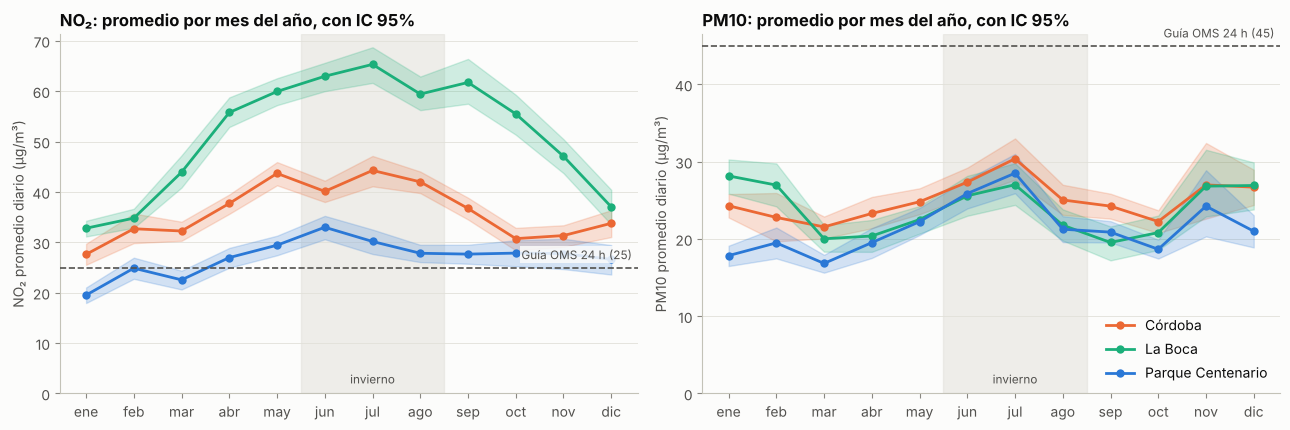

In [32]:
nombres_mes = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
d["estacion"] = d["id_estacion"].map(NOMBRE)
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.4))
for ax, cont, titulo in [(ejes[0], "no2", "NO₂"), (ejes[1], "pm10", "PM10")]:
    ax.axvspan(5.5, 8.5, color=GRILLA, alpha=0.5, zorder=0)
    ax.text(7, 0.02, "invierno", transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=8.5, color=TINTA_2)
    # seaborn promedia los días de cada mes y sombrea el intervalo de confianza del 95%
    sns.lineplot(data=d[d.id_contaminante == cont], x="mes", y="valor", hue="estacion", hue_order=ORDEN_NOMBRES,
                 palette=PALETA, marker="o", markersize=6, markeredgecolor="none", errorbar=("ci", 95), seed=0, ax=ax)
    linea_guia(ax, GUIA[(cont, "24h")], f"Guía OMS 24 h ({GUIA[(cont, '24h')]:.0f})")
    ax.set_xticks(range(1, 13), nombres_mes)
    ax.set_xlabel("")
    ax.set_ylim(0, None)
    ax.set_ylabel(f"{titulo} promedio diario (µg/m³)")
    ax.set_title(f"{titulo}: promedio por mes del año, con IC 95%")
    ax.grid(axis="x", visible=False)
    ax.legend(loc="lower right", title=None)
ejes[0].get_legend().remove()
fig.tight_layout()
guardar(fig, "10_estacionalidad")
plt.show()

In [33]:
(d[d.id_contaminante.isin(["no2", "pm10"])]
 .groupby(["id_contaminante", "id_estacion", "orden_estacion_del_anio", "estacion_del_anio"])
 .agg(dias=("valor", "size"), promedio=("valor", "mean"), pct_sobre_guia=("supera_guia", "mean"))
 .assign(pct_sobre_guia=lambda x: 100 * x.pct_sobre_guia).round(1)
 .droplevel("orden_estacion_del_anio"))

dias  promedio  pct_sobre_guia
id_contaminante id_estacion estacion_del_anio                                
no2             centenario  verano              213      23.0            32.4
                            otoño               180      26.3            46.7
                            invierno            153      30.3            73.2
                            primavera           116      27.7            58.6
                cordoba     verano              177      31.3            66.7
                            otoño               270      38.0            89.6
                            invierno            262      42.2            95.8
                            primavera           201      33.4            78.1
                la_boca     verano              238      34.6            81.5
                            otoño               257      53.2            98.4
                            invierno            260      62.6            99.6
                            primavera           189      55.5            99.5
pm10            centenario  verano              217      19.2             0.9
                            otoño               258      19.5             0.4
                            invierno            267      25.3             5.6
                            primavera           195      21.0             2.1
                cordoba     verano              176      24.6             3.4
                            otoño               250      23.2             0.4
                            invierno            237      27.9             7.2
                            primavera           192      24.4             2.1
                la_boca     verano              189      27.3             7.4
                            otoño               242      21.0             0.8
                            invierno            251      24.8             6.0
                            primavera           139      22.8             2.2

**Qué se concluye (subpregunta 5):**
- **Estacionalidad fuerte en el NO₂:** en invierno el promedio es **1,8 veces** el de verano en La Boca
  (62,6 contra 34,6 µg/m³) y ~1,3 veces en Córdoba y Centenario. En invierno La Boca supera la guía el 99,6% de los
  días y Córdoba el 96%. Es consistente con la menor dispersión atmosférica en los meses fríos (inversiones
  térmicas) y con más calefacción; sin datos meteorológicos no se puede separar cada efecto.
- El **PM10** varía poco con la época del año: sube algo en invierno, pero se mantiene debajo de la guía de 24 h.

## 8. Ritmo semanal

**Qué se busca:** el patrón de lunes a domingo, en el promedio de 24 h y en la ventana de actividad (8 a 16 h).

Figura guardada: reports/figures/11_ritmo_semanal.png


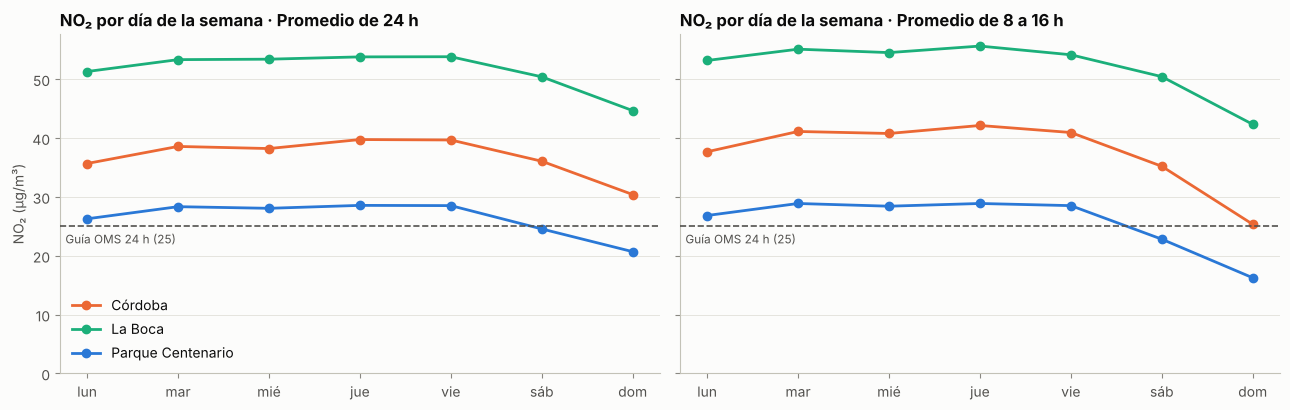

In [34]:
semana = (fact[(fact.id_contaminante == "no2") & fact.tiene_dato]
          .merge(dim_calendario[["fecha", "dia_semana"]], on="fecha")
          .groupby(["ventana", "id_estacion", "dia_semana"])["valor_masa"].mean().reset_index())
dias = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, ventana, titulo in [(ejes[0], "24h", "Promedio de 24 h"), (ejes[1], "8-16", "Promedio de 8 a 16 h")]:
    for e in ORDEN_ESTACIONES:
        s = semana[(semana.ventana == ventana) & (semana.id_estacion == e)]
        ax.plot(s.dia_semana, s.valor_masa, marker="o", markersize=6, color=COLOR_ESTACION[e], label=NOMBRE[e])
    linea_guia(ax, 25, "Guía OMS 24 h (25)", lado="izquierda", debajo=True)
    ax.set_xticks(range(1, 8), dias)
    ax.set_title(f"NO₂ por día de la semana · {titulo}")
    ax.grid(axis="x", visible=False)
ejes[0].set_ylabel("NO₂ (µg/m³)")
ejes[0].set_ylim(0, None)
ejes[0].legend(loc="lower left")
fig.tight_layout()
guardar(fig, "11_ritmo_semanal")
plt.show()

**Qué se concluye:** el NO₂ es estable de lunes a viernes y cae el fin de semana, sobre todo el domingo. En la
ventana de 8 a 16 h (la de mayor actividad) el patrón es parecido. La guía de 24 h se dibuja solo como referencia
visual en el panel de 8 a 16 h: la OMS la define sobre el promedio diario.

## 9. Correlación entre contaminantes por estación

**Qué se busca:** qué contaminantes se mueven juntos (pistas sobre fuentes comunes). Correlación de Spearman
(por rangos), más robusta que Pearson con distribuciones asimétricas y picos.

Figura guardada: reports/figures/12_correlaciones.png


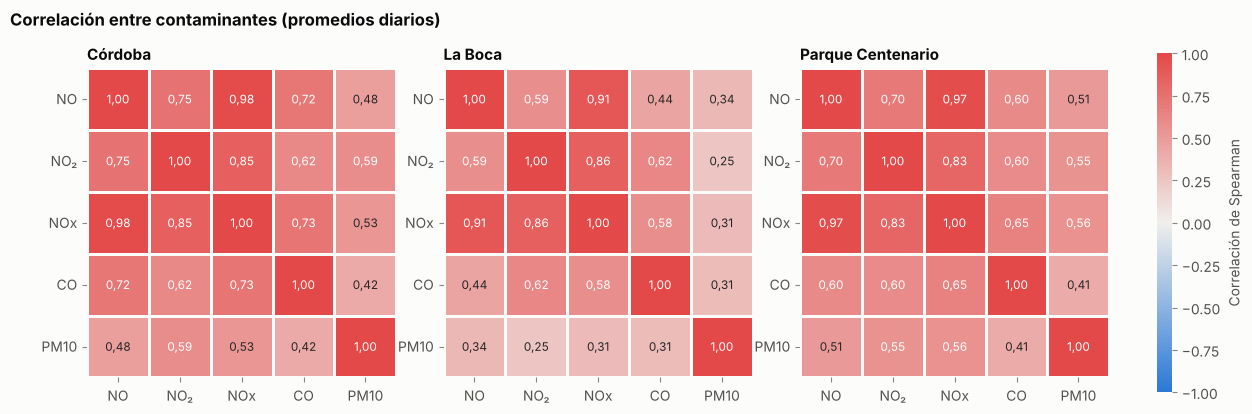

In [35]:
ancho24 = (fact[(fact.ventana == "24h") & fact.tiene_dato]
           .pivot_table(index=["id_estacion", "fecha"], columns="id_contaminante", values="valor_masa"))
orden_c = ["no", "no2", "nox", "co", "pm10"]
etiquetas_c = ["NO", "NO₂", "NOx", "CO", "PM10"]
cmap_div = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])
fig, ejes = plt.subplots(1, 4, figsize=(14, 4.4), gridspec_kw={"width_ratios": [1, 1, 1, 0.05]})
barra_ax = ejes[3]
for k, (ax, e) in enumerate(zip(ejes[:3], ORDEN_ESTACIONES)):
    corr = ancho24.loc[e][orden_c].corr(method="spearman")
    corr.index, corr.columns = etiquetas_c, etiquetas_c
    textos = corr.map(lambda v: coma(v, 2))  # coma decimal en las celdas
    sns.heatmap(corr, annot=textos, fmt="", cmap=cmap_div, vmin=-1, vmax=1, square=True, linewidths=2,
                linecolor=SUPERFICIE, cbar=k == 2, cbar_ax=barra_ax if k == 2 else None,
                cbar_kws={"label": "Correlación de Spearman"},
                annot_kws={"fontsize": 8.5}, ax=ax)
    ax.tick_params(axis="y", rotation=0)
    ax.set_title(NOMBRE[e], fontsize=11)
fig.suptitle("Correlación entre contaminantes (promedios diarios)", x=0.07, ha="left", fontweight="bold", fontsize=12)
guardar(fig, "12_correlaciones")
plt.show()

**Qué se concluye:**
- **NO y NOx** se mueven casi juntos (0,91 a 0,98) y el **NO₂** acompaña al NOx (0,83 a 0,86): la familia de los
  óxidos de nitrógeno comparte fuente (la combustión, sobre todo del tránsito). El NO₂ correlaciona algo menos con
  el NO porque es en parte secundario (se forma en el aire a partir del NO).
- El **CO** correlaciona de forma moderada con los óxidos de nitrógeno (0,44 a 0,73): fuentes en parte distintas
  (el CO sale sobre todo de los autos a nafta; el NOx, también del diésel).
- El **PM10** es el que menos se mueve con el resto, sobre todo en **La Boca (0,25 a 0,34)**: depende también de
  fuentes regionales, del viento y del polvo. Correlación no implica causalidad.

## 10. ¿Cuánto condicionan los huecos de datos a las conclusiones? (subpregunta 6)

**Qué se busca:** si un análisis que ignora la calidad de los datos llegaría a una conclusión equivocada.
Ejemplo: "el NO₂ bajó de 2024 a 2026". Se comparan los mismos meses (enero a septiembre) para no mezclar la
estacionalidad.

In [36]:
ene_sep = fact[(fact.id_contaminante == "no2") & (fact.ventana == "24h") & fact.tiene_dato
               & (pd.to_datetime(fact.fecha).dt.month <= 9)].copy()
ene_sep["anio"] = pd.to_datetime(ene_sep.fecha).dt.year
por_estacion = ene_sep.pivot_table(index="id_estacion", columns="anio", values="valor_masa", aggfunc="mean")
dias_est = ene_sep.pivot_table(index="id_estacion", columns="anio", values="valor_masa", aggfunc="size")
juntas = ene_sep.groupby("anio")["valor_masa"].mean()
print("Promedio ene-sep por estación (µg/m³):"); print(por_estacion.round(1).to_string())
print("\nDías con dato:"); print(dias_est.to_string())
print("\nLas tres estaciones juntas (µg/m³):", juntas.round(1).to_dict())

Promedio ene-sep por estación (µg/m³):
anio         2024  2025  2026
id_estacion                  
centenario   25.3  27.7  25.2
cordoba      42.0  36.6  36.2
la_boca      58.8  51.8  46.7

Días con dato:
anio         2024  2025  2026
id_estacion                  
centenario     40   240   269
cordoba       221   246   265
la_boca       264   272   232

Las tres estaciones juntas (µg/m³): {2024: 49.1, 2025: 39.3, 2026: 35.5}


Figura guardada: reports/figures/13_ene_sep_composicion.png


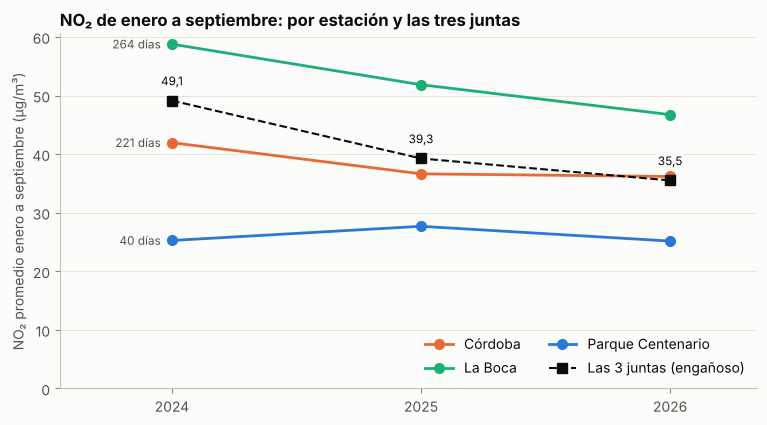

In [37]:
fig, ax = plt.subplots(figsize=(9, 4.6))
anios = [2024, 2025, 2026]
for e in ORDEN_ESTACIONES:
    ax.plot(anios, por_estacion.loc[e, anios], marker="o", markersize=7, color=COLOR_ESTACION[e], label=NOMBRE[e])
    ax.annotate(f"{dias_est.loc[e, 2024]} días", (2024, por_estacion.loc[e, 2024]), xytext=(-8, 0),
                textcoords="offset points", ha="right", va="center", fontsize=8.5, color=TINTA_2)
ax.plot(anios, juntas.loc[anios], marker="s", markersize=7, color=TINTA, linestyle="--", linewidth=1.5,
        label="Las 3 juntas (engañoso)")
for a in anios:
    ax.annotate(coma(juntas.loc[a]), (a, juntas.loc[a]), xytext=(0, 9), textcoords="offset points",
                ha="center", va="bottom", fontsize=8.5, color=TINTA,
                bbox=dict(facecolor=SUPERFICIE, edgecolor="none", alpha=0.85, pad=1))
ax.set_xticks(anios, ["2024", "2025", "2026"])
ax.set_xlim(2023.55, 2026.35)
ax.set_ylim(0, None)
ax.set_ylabel("NO₂ promedio enero a septiembre (µg/m³)")
ax.set_title("NO₂ de enero a septiembre: por estación y las tres juntas")
ax.legend(loc="lower right", ncol=2)
ax.grid(axis="x", visible=False)
guardar(fig, "13_ene_sep_composicion")
plt.show()

**Qué se concluye (subpregunta 6):**
- Juntando las tres estaciones, el NO₂ de enero a septiembre "baja" de **49,1 a 35,5 µg/m³** (26,1 → 18,9 ppb),
  una caída de **28%**. Pero en 2024 **Centenario, la estación más limpia, tiene solo 40 días** (contra 240 o más en los
  otros años): el promedio de 2024 sale inflado porque pesan más La Boca y Córdoba.
- **Por estación**, la baja es menor: **La Boca −20%** y **Córdoba −14%** de 2024 a 2026, y **Centenario no muestra
  tendencia**. Y sin controlar la meteorología (un invierno más ventoso o lluvioso baja el NO₂) no se puede atribuir
  a una mejora real.
- Lección: **los huecos de datos no solo restan precisión, pueden cambiar la conclusión**. Por eso cada indicador
  se informa con su `n` y la regla del 75% deja afuera los años incompletos.

## 11. Conclusiones exploratorias

**Respuesta a la pregunta:** ninguna estación cumple las guías de la OMS para el NO₂, pero **Parque Centenario y
Córdoba están en los escalones intermedios** (IT2 e IT1 en el promedio anual) y **La Boca no alcanza ni el primero**.
El PM10 está más cerca de la guía y el CO no es un problema.

| | NO₂ | PM10 | CO |
|---|---|---|---|
| Escalón OMS anual (últimos 12 meses) | IT2 (Centenario), IT1 (Córdoba), > IT1 (La Boca) | IT3 en las tres | — |
| Días que cumplen el IT2 diario (NO₂: 50 µg/m³) | 98,6% (Centenario), 87,7% (Córdoba), 49,7% (La Boca) | — | — |
| % de días sobre la guía de 24 h | 50% (Centenario) a 95% (La Boca) | 2% a 4% | 0% |
| Promedio de los últimos 12 meses vs. guía anual | 2,6 a 4,6 veces | 1,5 a 1,8 veces | sin guía anual |
| P99 anual vs. guía de 24 h | 1,7 a 4,2 veces | 1,0 a 1,4 veces | < 0,4 veces |

**Hipótesis:**
- **H1 se sostiene en dos de las tres estaciones:** en Parque Centenario y Córdoba el NO₂ cumple el IT2 diario la
  gran mayoría de los días (98,6% y 87,7%) y el promedio anual cumple al menos el IT1. **En La Boca no**: solo la
  mitad de los días cumple el IT2 y el promedio anual supera el IT1. El PM10 cumple la guía diaria el 96-98% de los
  días, **pero no cumple la guía anual ni la de 24 h en su definición formal (P99)**.
- **H2 se sostiene:** La Boca es la estación más comprometida en NO₂ con todos los indicadores (% de días, promedio
  anual, P99, racha de 216 días). Es la única por encima del objetivo intermedio menos exigente (IT1).
- **H3 se sostiene a medias:** domingos y feriados el NO₂ baja entre 16% y 27%, pero en La Boca el 90% de los
  domingos sigue por encima de la guía.

**Otros hallazgos:** fuerte estacionalidad del NO₂ (invierno ~1,8 veces el verano en La Boca); los días más extremos
son episodios compartidos por las tres estaciones; la aparente baja de 2024 a 2026 está inflada por los huecos de
datos.

**Limitaciones:**
- **Solo 3 estaciones**: no representan a toda la Ciudad (no hay estaciones en el sur-oeste ni en el norte).
- **Huecos de datos**, en especial el NO₂ de Centenario en 2024; los indicadores anuales con menos de 75% de días
  no se calculan.
- **2026 es parcial** (enero a septiembre): se compara con los últimos 12 meses, no con el año calendario.
- **Sin control meteorológico**: las diferencias entre períodos o estaciones del año pueden deberse al clima.
- La guía de 24 h es estadísticamente un **P99 anual**; el "% de días" es una simplificación para comunicar.
- Los datos de entrada son **promedios diarios y por bloques de 8 h publicados por la APrA** (calculados por la
  agencia a partir de mediciones horarias); el TP no tiene acceso a los datos horarios y el ETL arranca de esos
  informes. Los valores vienen redondeados (NO₂ en ppb enteros).
- La conversión de ppb a µg/m³ supone 25 °C y 1 atm (convención de la OMS).